In [1]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer
!pip install qiskit qiskit-aer matplotlib numpy
!pip install qiskit-machine-learning
!pip install pennylane scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 94.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 82.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 70.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 14.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 109.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 54.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 69.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7

STEP 2. Experiment Setting
Target : 1
Shots : 1000
Theta List : [0.1, 1.0, 2.5]


STEP 3. Quantum Circuit
     ┌─────────┐┌─┐
  q: ┤ Ry(0.1) ├┤M├
     └─────────┘└╥┘
c: 1/════════════╩═
                 0 


STEP 4. Simulator
AerSimulator('aer_simulator')


STEP 5. Single Parameter Test
{'1': 234, '0': 766}


STEP 6. Prediction
P(0) : 0.766
P(1) : 0.234
Prediction : 0.234


STEP 7. Loss
Target : 1
Prediction : 0.234
Loss : 0.586756


STEP 8. Parameter Change
--------------------------------
Theta : 0.1
Counts : {'1': 4, '0': 996}
Prediction : 0.004
Loss : 0.992016
--------------------------------
Theta : 1.0
Counts : {'1': 232, '0': 768}
Prediction : 0.232
Loss : 0.589824
--------------------------------
Theta : 2.5
Counts : {'0': 91, '1': 909}
Prediction : 0.909
Loss : 0.008280999999999995


STEP 9. Result Table
Theta	Prediction	Loss
0.10	0.004		0.9920
1.00	0.232		0.5898
2.50	0.909		0.0083


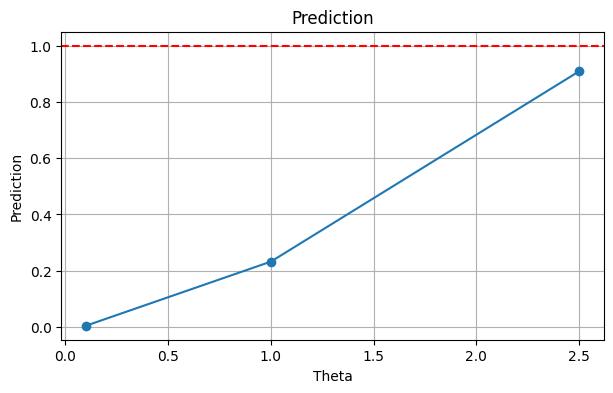

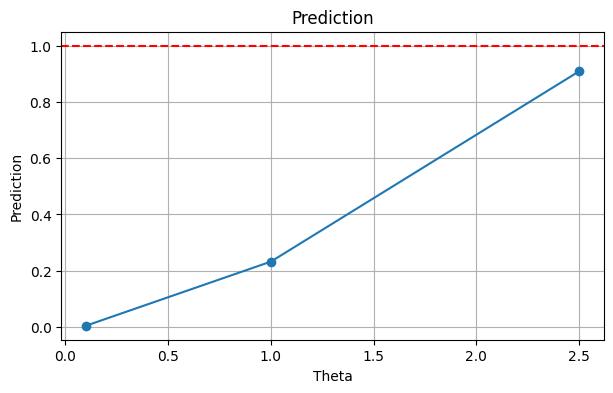

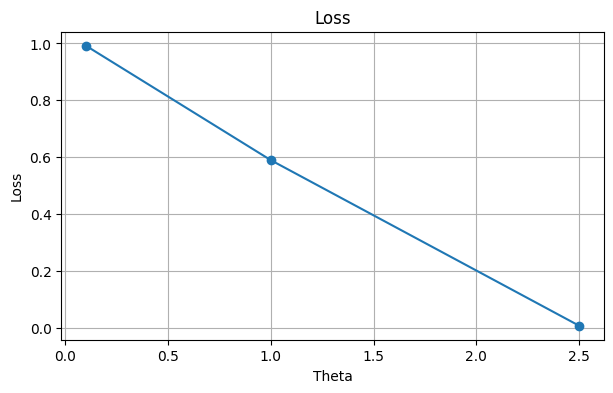

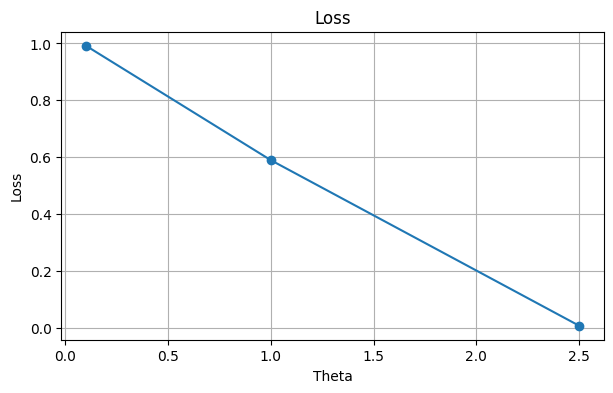



STEP 12. Best Parameter
Best Theta : 2.5
Prediction : 0.909
Loss : 0.008280999999999995


In [3]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit import transpile

from qiskit_aer import AerSimulator

print("=" * 70)
print("STEP 2. Experiment Setting")
print("=" * 70)

shots = 1000

target = 1

theta_list = [0.1, 1.0, 2.5]

print("Target :", target)
print("Shots :", shots)
print("Theta List :", theta_list)

print("\n")
print("=" * 70)
print("STEP 3. Quantum Circuit")
print("=" * 70)

theta = theta_list[0]

qc = QuantumCircuit(1,1)

qc.ry(theta,0)

qc.measure(0,0)

print(qc.draw())

print("\n")
print("=" * 70)
print("STEP 4. Simulator")
print("=" * 70)

simulator = AerSimulator()

print(simulator)

print("\n")
print("=" * 70)
print("STEP 5. Single Parameter Test")
print("=" * 70)

theta = 1.0

qc = QuantumCircuit(1,1)

qc.ry(theta,0)

qc.measure(0,0)

compiled = transpile(qc, simulator)

job = simulator.run(
    compiled,
    shots=shots
)

result = job.result()

counts = result.get_counts()

print(counts)

print("\n")
print("=" * 70)
print("STEP 6. Prediction")
print("=" * 70)

count0 = counts.get("0",0)
count1 = counts.get("1",0)

p0 = count0/shots
p1 = count1/shots

prediction = p1

print("P(0) :",p0)
print("P(1) :",p1)

print("Prediction :",prediction)

print("\n")
print("=" * 70)
print("STEP 7. Loss")
print("=" * 70)

loss = (prediction-target)**2

print("Target :",target)

print("Prediction :",prediction)

print("Loss :",loss)



print("\n")
print("=" * 70)
print("STEP 8. Parameter Change")
print("=" * 70)

results = []

for theta in theta_list:

    qc = QuantumCircuit(1,1)

    qc.ry(theta,0)

    qc.measure(0,0)

    compiled = transpile(qc, simulator)

    job = simulator.run(
        compiled,
        shots=shots
    )

    result = job.result()

    counts = result.get_counts()

    p1 = counts.get("1",0)/shots

    prediction = p1

    loss = (prediction-target)**2

    print("--------------------------------")

    print("Theta :",theta)

    print("Counts :",counts)

    print("Prediction :",prediction)

    print("Loss :",loss)

    results.append([
        theta,
        prediction,
        loss
    ])


print("\n")
print("=" * 70)
print("STEP 9. Result Table")
print("=" * 70)

print("Theta\tPrediction\tLoss")

for row in results:

    print(f"{row[0]:.2f}\t{row[1]:.3f}\t\t{row[2]:.4f}")


theta_plot = [r[0] for r in results]
prediction_plot = [r[1] for r in results]

fig1 = plt.figure(figsize=(7,4))

plt.plot(
    theta_plot,
    prediction_plot,
    marker='o'
)

plt.axhline(
    target,
    linestyle='--',
    color='red'
)

plt.title("Prediction")

plt.xlabel("Theta")

plt.ylabel("Prediction")

plt.grid()
display(fig1)
plt.show()



loss_plot = [r[2] for r in results]

fig2 = plt.figure(figsize=(7,4))

plt.plot(
    theta_plot,
    loss_plot,
    marker='o'
)

plt.title("Loss")

plt.xlabel("Theta")

plt.ylabel("Loss")

plt.grid()
display(fig2)
plt.show()


print("\n")
print("=" * 70)
print("STEP 12. Best Parameter")
print("=" * 70)

best = min(
    results,
    key=lambda x:x[2]
)

print("Best Theta :",best[0])

print("Prediction :",best[1])

print("Loss :",best[2])
